In [32]:
!pip install openpyxl


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel(r"data/Telco_customer_churn.xlsx")

In [34]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [35]:
df.shape

(7043, 33)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [37]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [38]:
df.describe(include="object")

,CustomerID,Country,State,City,Lat Long,Gender,Senior Citizen,Partner,Dependents,Phone Service,...,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Total Charges,Churn Label,Churn Reason
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043,7043,1869
unique,7043,1,1,1129,1652,2,2,2,2,2,...,3,3,3,3,3,2,4,6531,2,20
top,3186-AJIEK,United States,California,Los Angeles,"34.02381, -118.156582",Male,No,No,No,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,,No,Attitude of support person
freq,1,7043,7043,305,5,3555,5901,3641,5416,6361,...,3095,3473,2810,2785,3875,4171,2365,11,5174,192


In [39]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [40]:
df.duplicated().sum()

np.int64(0)

In [41]:
df["Churn Label"].value_counts()

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

In [42]:
df["Churn Label"].value_counts(normalize=True) * 100

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [43]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')

In [44]:
drop_cols = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
    "Churn Value",
    "Churn Score",
    "Churn Reason",
    "CLTV"
]

df = df.drop(columns=drop_cols)

In [45]:
df.shape

(7043, 20)

In [46]:
df.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes


In [47]:
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce"
)

In [48]:
df["Total Charges"].isnull().sum()

np.int64(11)

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             7043 non-null   object 
 1   Senior Citizen     7043 non-null   object 
 2   Partner            7043 non-null   object 
 3   Dependents         7043 non-null   object 
 4   Tenure Months      7043 non-null   int64  
 5   Phone Service      7043 non-null   object 
 6   Multiple Lines     7043 non-null   object 
 7   Internet Service   7043 non-null   object 
 8   Online Security    7043 non-null   object 
 9   Online Backup      7043 non-null   object 
 10  Device Protection  7043 non-null   object 
 11  Tech Support       7043 non-null   object 
 12  Streaming TV       7043 non-null   object 
 13  Streaming Movies   7043 non-null   object 
 14  Contract           7043 non-null   object 
 15  Paperless Billing  7043 non-null   object 
 16  Payment Method     7043 

In [50]:
df.isnull().sum()

Gender                0
Senior Citizen        0
Partner               0
Dependents            0
Tenure Months         0
Phone Service         0
Multiple Lines        0
Internet Service      0
Online Security       0
Online Backup         0
Device Protection     0
Tech Support          0
Streaming TV          0
Streaming Movies      0
Contract              0
Paperless Billing     0
Payment Method        0
Monthly Charges       0
Total Charges        11
Churn Label           0
dtype: int64

In [51]:
df = df.dropna(subset=["Total Charges"])

In [52]:
df.shape

(7032, 20)

In [53]:
df.isnull().sum().sum()

np.int64(0)

In [54]:
df["Churn Label"].value_counts()

Churn Label
No     5163
Yes    1869
Name: count, dtype: int64

In [55]:
df["Churn Label"].value_counts(normalize=True) * 100

Churn Label
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64

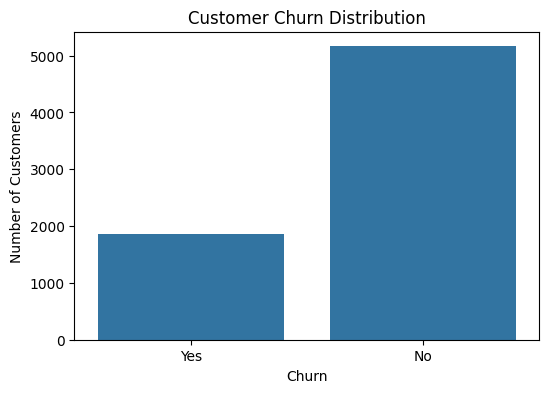

In [56]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn Label")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

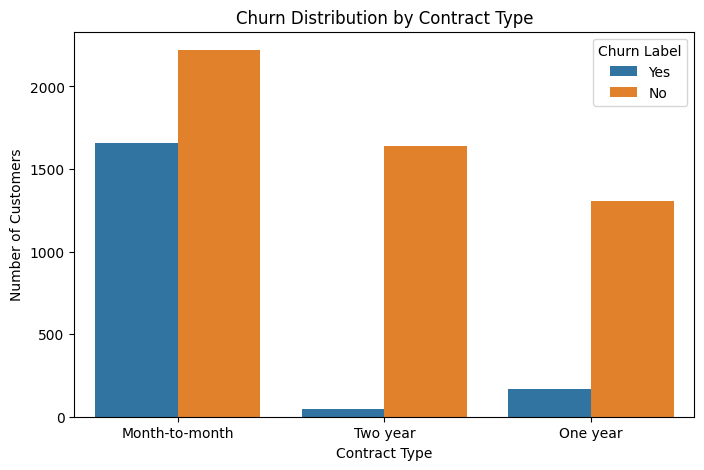

In [57]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn Label"
)

plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

In [58]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn Label"],
    normalize="index"
) * 100

contract_churn

Churn Label,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.722826,11.277174
Two year,97.151335,2.848665


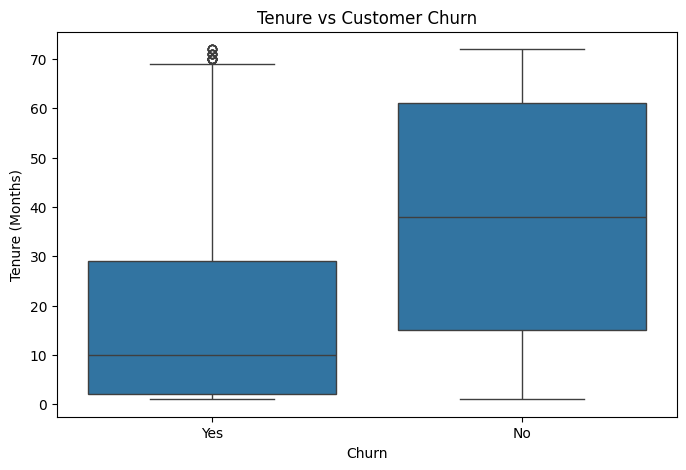

In [59]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn Label",
    y="Tenure Months"
)

plt.title("Tenure vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [60]:
df.groupby("Churn Label")["Tenure Months"].mean()

Churn Label
No     37.650010
Yes    17.979133
Name: Tenure Months, dtype: float64

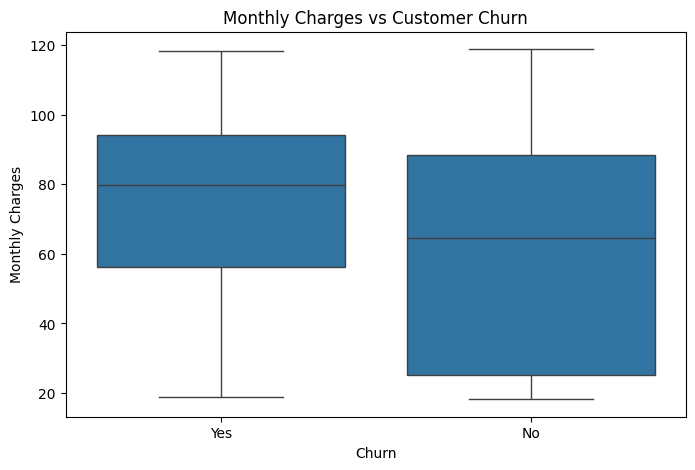

In [61]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn Label",
    y="Monthly Charges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [62]:
df.groupby("Churn Label")["Monthly Charges"].mean()

Churn Label
No     61.307408
Yes    74.441332
Name: Monthly Charges, dtype: float64

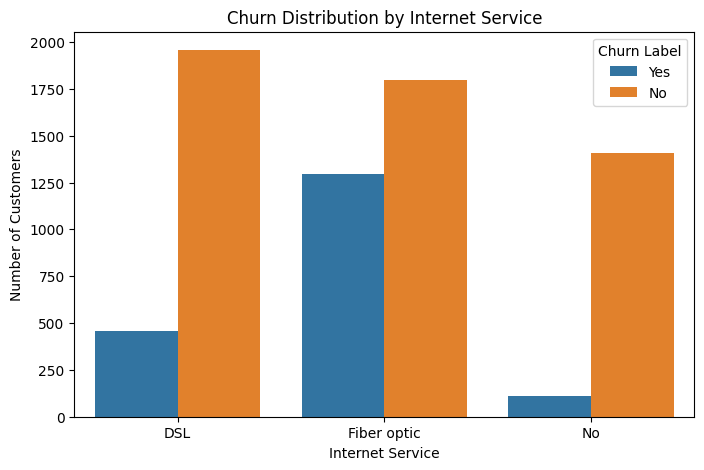

In [63]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Internet Service",
    hue="Churn Label"
)

plt.title("Churn Distribution by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [64]:
internet_churn = pd.crosstab(
    df["Internet Service"],
    df["Churn Label"],
    normalize="index"
) * 100

internet_churn

Churn Label,No,Yes
Internet Service,,
DSL,81.001656,18.998344
Fiber optic,58.107235,41.892765
No,92.565789,7.434211


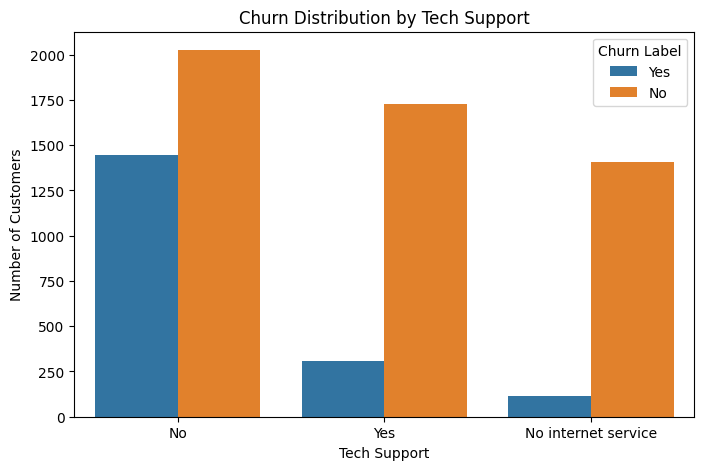

In [65]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Tech Support",
    hue="Churn Label"
)

plt.title("Churn Distribution by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Number of Customers")

plt.show()

In [66]:
tech_support_churn = pd.crosstab(
    df["Tech Support"],
    df["Churn Label"],
    normalize="index"
) * 100

tech_support_churn

Churn Label,No,Yes
Tech Support,,
No,58.352535,41.647465
No internet service,92.565789,7.434211
Yes,84.803922,15.196078


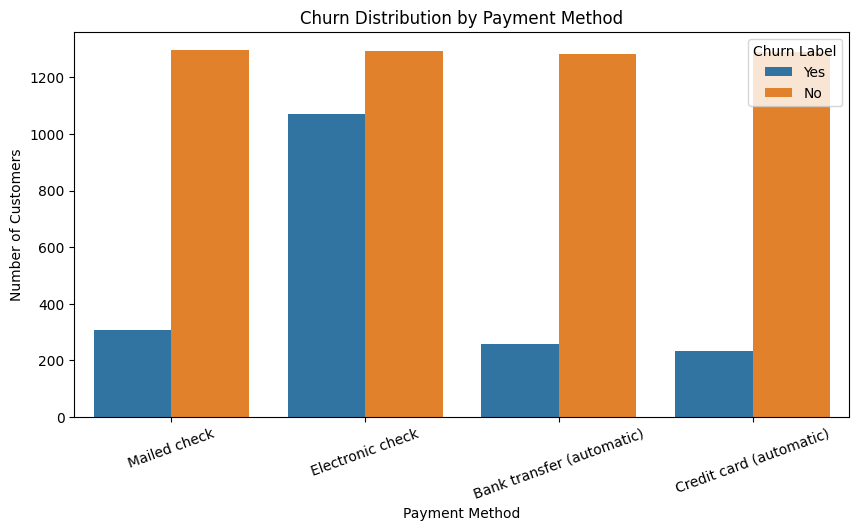

In [67]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Payment Method",
    hue="Churn Label"
)

plt.title("Churn Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

In [68]:
payment_churn = pd.crosstab(
    df["Payment Method"],
    df["Churn Label"],
    normalize="index"
) * 100

payment_churn

Churn Label,No,Yes
Payment Method,,
Bank transfer (automatic),83.268482,16.731518
Credit card (automatic),84.746877,15.253123
Electronic check,54.714588,45.285412
Mailed check,80.798005,19.201995


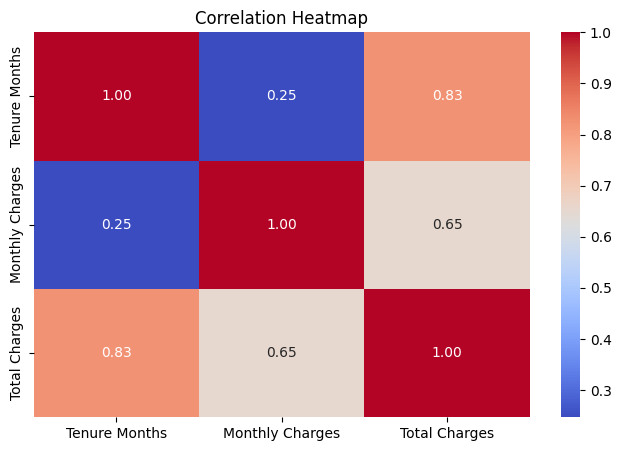

In [69]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.select_dtypes(include=["int64", "float64"]).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [70]:
from scipy.stats import chi2_contingency

table = pd.crosstab(
    df["Contract"],
    df["Churn Label"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square statistic:", chi2)
print("p-value:", p)

Chi-square statistic: 1179.5458287339445
p-value: 7.326182186265472e-257


In [71]:
if p < 0.05:
    print("Reject H0: Contract type is significantly associated with churn.")
else:
    print("Fail to reject H0: No significant association found.")

Reject H0: Contract type is significantly associated with churn.


In [72]:
from scipy.stats import chi2_contingency

table = pd.crosstab(
    df["Tech Support"],
    df["Churn Label"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square statistic:", chi2)
print("p-value:", p)

if p < 0.05:
    print("Reject H0: Tech Support is significantly associated with churn.")
else:
    print("Fail to reject H0: No significant association found.")

Chi-square statistic: 824.925564387502
p-value: 7.407807748843711e-180
Reject H0: Tech Support is significantly associated with churn.


In [73]:
df["Churn Label"] = df["Churn Label"].map({
    "No": 0,
    "Yes": 1
})

In [74]:
df["Churn Label"].value_counts()

Churn Label
0    5163
1    1869
Name: count, dtype: int64

In [75]:
X = df.drop("Churn Label", axis=1)
y = df["Churn Label"]

In [76]:
print(X.shape)
print(y.shape)

(7032, 19)
(7032,)


In [77]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5625, 19)
Testing data: (1407, 19)


In [78]:
categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns

print("Categorical columns:")
print(list(categorical_cols))

print("\nNumerical columns:")
print(list(numerical_cols))

Categorical columns:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']

Numerical columns:
['Tenure Months', 'Monthly Charges', 'Total Charges']


In [79]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_cols
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ]
)

In [80]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [81]:
y_pred = logistic_model.predict(X_test)

In [82]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

y_prob = logistic_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Logistic Regression Results
---------------------------
Accuracy : 0.8045
Precision: 0.641
Recall   : 0.6016
F1 Score : 0.6207
ROC-AUC  : 0.8431


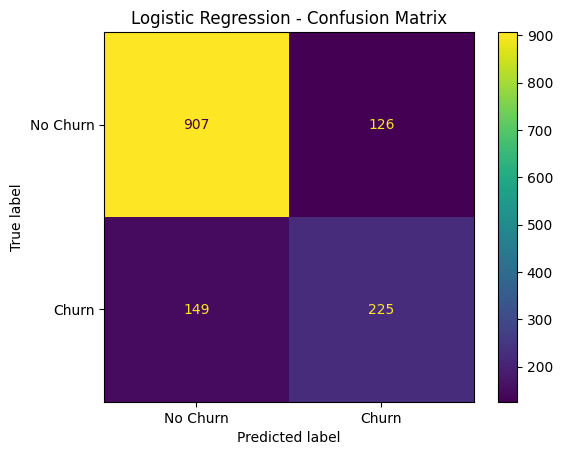

In [83]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [84]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [85]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1 Score :", round(f1_rf, 4))
print("ROC-AUC  :", round(roc_auc_rf, 4))

Random Forest Results
---------------------
Accuracy : 0.7939
Precision: 0.6355
Recall   : 0.5267
F1 Score : 0.576
ROC-AUC  : 0.8271


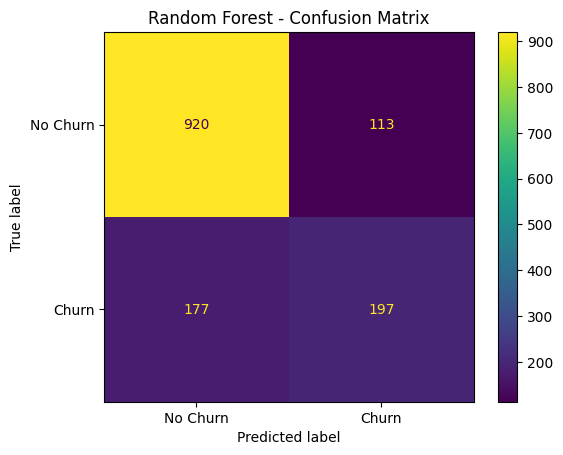

In [86]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [87]:
!pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.8/101.7 MB 859.5 kB/s eta 0:01:58
    --------------------------------------- 1.6/101.7 MB 1.5 MB/s eta 0:01:07
    --------------------------------------- 1.6/101.7 MB 1.5 MB/s eta 0:01:07
    --------------------------------------- 1.6/101.7 MB 1.5 MB/s eta 0:01:07
    --------------------------------------- 2.1/101.7 MB 1.3 MB/s eta 0:01:19
    --------------------------------------- 2.1/101.7 MB 1.3 MB/s eta 0:01:19
    --------------------------------------- 2.4/101.7 MB 1.1 MB/s eta 0:01:32
   - -------------------------------------- 2.6/101.7 MB 1.1 MB/s eta 0:01:27
   - --------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [88]:
from xgboost import XGBClassifier

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        random_state=42,
        eval_metric="logloss"
    ))
])

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [89]:
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("XGBoost Results")
print("----------------")
print("Accuracy :", round(accuracy_xgb, 4))
print("Precision:", round(precision_xgb, 4))
print("Recall   :", round(recall_xgb, 4))
print("F1 Score :", round(f1_xgb, 4))
print("ROC-AUC  :", round(roc_auc_xgb, 4))

XGBoost Results
----------------
Accuracy : 0.7982
Precision: 0.6355
Recall   : 0.5642
F1 Score : 0.5977
ROC-AUC  : 0.8466


In [90]:
logistic_weighted = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

logistic_weighted.fit(X_train, y_train)

y_pred_weighted = logistic_weighted.predict(X_test)
y_prob_weighted = logistic_weighted.predict_proba(X_test)[:, 1]

In [91]:
print("Weighted Logistic Regression")
print("----------------------------")
print("Accuracy :", round(accuracy_score(y_test, y_pred_weighted), 4))
print("Precision:", round(precision_score(y_test, y_pred_weighted), 4))
print("Recall   :", round(recall_score(y_test, y_pred_weighted), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_weighted), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_weighted), 4))

Weighted Logistic Regression
----------------------------
Accuracy : 0.7292
Precision: 0.4941
Recall   : 0.7861
F1 Score : 0.6068
ROC-AUC  : 0.8425


In [92]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_prob = logistic_model.predict_proba(X_test)[:, 1]

for threshold in [0.50, 0.45, 0.40, 0.35, 0.30]:
    
    y_pred_threshold = (y_prob >= threshold).astype(int)
    
    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)
    
    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold: 0.50 | Precision: 0.6410 | Recall: 0.6016 | F1: 0.6207
Threshold: 0.45 | Precision: 0.6156 | Recall: 0.6551 | F1: 0.6347
Threshold: 0.40 | Precision: 0.5791 | Recall: 0.6952 | F1: 0.6318
Threshold: 0.35 | Precision: 0.5451 | Recall: 0.7273 | F1: 0.6231
Threshold: 0.30 | Precision: 0.5184 | Recall: 0.7540 | F1: 0.6144


In [93]:
from sklearn.metrics import classification_report

y_pred_final = (y_prob >= 0.45).astype(int)

print(classification_report(
    y_test,
    y_pred_final,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.87      0.85      0.86      1033
       Churn       0.62      0.66      0.63       374

    accuracy                           0.80      1407
   macro avg       0.74      0.75      0.75      1407
weighted avg       0.80      0.80      0.80      1407



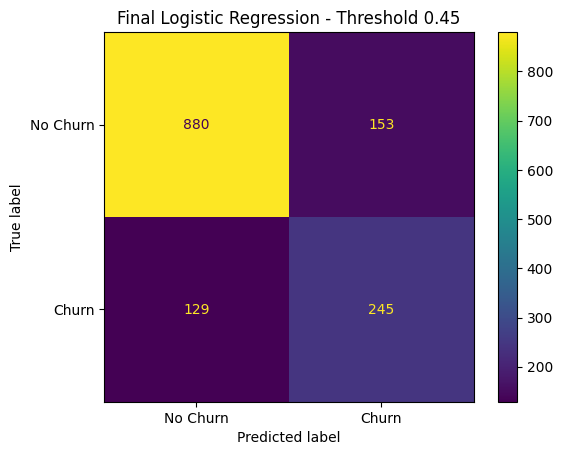

In [94]:
cm_final = confusion_matrix(y_test, y_pred_final)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Final Logistic Regression - Threshold 0.45")
plt.show()

In [95]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 1.0],
    "model__scale_pos_weight": [1, 2, 2.77],  # ~ratio of No:Yes churn
}

search = RandomizedSearchCV(
    xgb_model, param_grid, n_iter=30, scoring="f1",
    cv=5, random_state=42, n_jobs=-1
)
search.fit(X_train, y_train)

,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'model__colsample_bytree': [0.7, 0.8, ...], 'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [3, 4, ...], 'model__n_estimators': [100, 200, ...], ...}"
,n_iter,30
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [96]:
df["Total Services"] = df[["Online Security","Online Backup","Device Protection",
                            "Tech Support","Streaming TV","Streaming Movies"]].apply(
    lambda x: (x == "Yes").sum(), axis=1
)
df["Avg Monthly Spend"] = df["Total Charges"] / df["Tenure Months"].replace(0, 1)
df["Tenure Group"] = pd.cut(df["Tenure Months"], bins=[0,12,24,48,72],
                             labels=["0-1yr","1-2yr","2-4yr","4-6yr"])

In [97]:
from sklearn.model_selection import cross_validate
scores = cross_validate(xgb_model, X, y, cv=5,
                         scoring=["accuracy","precision","recall","f1","roc_auc"])

In [98]:
from sklearn.ensemble import StackingClassifier
stack = StackingClassifier(
    estimators=[("lr", logistic_weighted), ("rf", rf_model), ("xgb", xgb_model)],
    final_estimator=LogisticRegression(), cv=5
)

In [99]:
print("Best params:", search.best_params_)
print("Best CV F1:", search.best_score_)

best_xgb = search.best_estimator_
y_pred_best = best_xgb.predict(X_test)
y_prob_best = best_xgb.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall   :", recall_score(y_test, y_pred_best))
print("F1 Score :", f1_score(y_test, y_pred_best))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_best))

Best params: {'model__subsample': 0.7, 'model__scale_pos_weight': 2, 'model__n_estimators': 300, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}
Best CV F1: 0.6522644474526835
Accuracy : 0.7640369580668088
Precision: 0.5403846153846154
Recall   : 0.7513368983957219
F1 Score : 0.6286353467561522
ROC-AUC  : 0.8473502751448198


In [100]:
print(df.columns.tolist())   # should include "Total Services", "Avg Monthly Spend", "Tenure Group"
print(X_train.columns.tolist())  # should also include them — if not, redo the split

['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Total Services', 'Avg Monthly Spend', 'Tenure Group']
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges']


In [101]:
print("Accuracy :", scores["test_accuracy"].mean(), "±", scores["test_accuracy"].std())
print("Precision:", scores["test_precision"].mean(), "±", scores["test_precision"].std())
print("Recall   :", scores["test_recall"].mean(), "±", scores["test_recall"].std())
print("F1       :", scores["test_f1"].mean(), "±", scores["test_f1"].std())
print("ROC-AUC  :", scores["test_roc_auc"].mean(), "±", scores["test_roc_auc"].std())

Accuracy : 0.8078768927158558 ± 0.009698814397841702
Precision: 0.6653472765910625 ± 0.025400756358612577
Recall   : 0.5596622270648449 ± 0.013435198191392434
F1       : 0.6077287039961645 ± 0.01548526231917155
ROC-AUC  : 0.8541002235928191 ± 0.01516801665843828


In [102]:
stack.fit(X_train, y_train)
y_pred_stack = stack.predict(X_test)
y_prob_stack = stack.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_stack))
print("Precision:", precision_score(y_test, y_pred_stack))
print("Recall   :", recall_score(y_test, y_pred_stack))
print("F1 Score :", f1_score(y_test, y_pred_stack))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_stack))

Accuracy : 0.8081023454157783
Precision: 0.6468926553672316
Recall   : 0.6122994652406417
F1 Score : 0.6291208791208791
ROC-AUC  : 0.8472609760264223


In [103]:
# Feature Engineering

df["Total Services"] = df[
    [
        "Online Security",
        "Online Backup",
        "Device Protection",
        "Tech Support",
        "Streaming TV",
        "Streaming Movies"
    ]
].apply(lambda x: (x == "Yes").sum(), axis=1)

df["Avg Monthly Spend"] = (
    df["Total Charges"] / df["Tenure Months"].replace(0, 1)
)

df["Tenure Group"] = pd.cut(
    df["Tenure Months"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-1yr", "1-2yr", "2-4yr", "4-6yr"]
)

In [104]:
X = df.drop("Churn Label", axis=1)
y = df["Churn Label"]

In [105]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [106]:
print("X shape:", X.shape)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print(X_train.columns.tolist())

X shape: (7032, 22)
Training shape: (5625, 22)
Testing shape: (1407, 22)
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Total Services', 'Avg Monthly Spend', 'Tenure Group']


In [107]:
df = df.drop(columns=["Avg Monthly Spend"])

In [108]:
X = df.drop("Churn Label", axis=1)
y = df["Churn Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [109]:
df["Total Services"] = df[
    [
        "Online Security",
        "Online Backup",
        "Device Protection",
        "Tech Support",
        "Streaming TV",
        "Streaming Movies"
    ]
].apply(lambda x: (x == "Yes").sum(), axis=1)

df["Tenure Group"] = pd.cut(
    df["Tenure Months"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-1yr", "1-2yr", "2-4yr", "4-6yr"]
)

In [110]:
X = df.drop("Churn Label", axis=1)
y = df["Churn Label"]

In [111]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [112]:
print("X shape:", X.shape)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nColumns:")
print(X_train.columns.tolist())

X shape: (7032, 21)
Training shape: (5625, 21)
Testing shape: (1407, 21)

Columns:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Total Services', 'Tenure Group']


In [113]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

In [114]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [115]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 0.7974413646055437
Precision: 0.636085626911315
Recall   : 0.5561497326203209
F1 Score : 0.5934379457917262
ROC-AUC  : 0.842552712363657


In [116]:
y_pred_final = (y_prob >= 0.45).astype(int)

print("Accuracy :", accuracy_score(y_test, y_pred_final))
print("Precision:", precision_score(y_test, y_pred_final))
print("Recall   :", recall_score(y_test, y_pred_final))
print("F1 Score :", f1_score(y_test, y_pred_final))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 0.7931769722814499
Precision: 0.6061381074168798
Recall   : 0.6336898395721925
F1 Score : 0.6196078431372549
ROC-AUC  : 0.842552712363657
